## Latihan Mandiri 4 - Asyncio - Pemrograman Asinkron

**Nama: Fathiya Dhiyaul Izzaty   
NIM: 2411513037**

## Latihan Mandiri 4 - Asyncio - Pemrograman Asinkron

**Nama: Fathiya Dhiyaul Izzaty   
NIM: 2411513037**

**1.** Perbesar `daftar_paket_banyak` menjadi 20–30 nama paket PyPI valid (cari sendiri nama-nama package populer). Bandingkan waktu total untuk `BATAS_KONKURENSI` = 1, 3, 5, 10, 20. Plot waktu vs batas konkurensi. Pada titik berapa penambahan batas konkurensi mulai memberi manfaat yang sangat kecil? Kaitkan dengan konsep *diminishing returns* dari Hukum Amdahl (Pertemuan 1).
**Jawaban :**
daftar_paket_banyak yang digunakan,yaitu 25 paket PyPI dimana tiap batas dijalankan 3 kali lalu dirata-rata, dan ada satu kali pemanasan di awal yang tidak dihitung.

=== Memulai Eksperimen Skala ===
BATAS_KONKURENSI =  1 | Waktu Total: 1.5817 detik
BATAS_KONKURENSI =  3 | Waktu Total: 0.7481 detik
BATAS_KONKURENSI =  5 | Waktu Total: 0.6844 detik
BATAS_KONKURENSI = 10 | Waktu Total: 0.8592 detik
BATAS_KONKURENSI = 20 | Waktu Total: 0.4090 detik


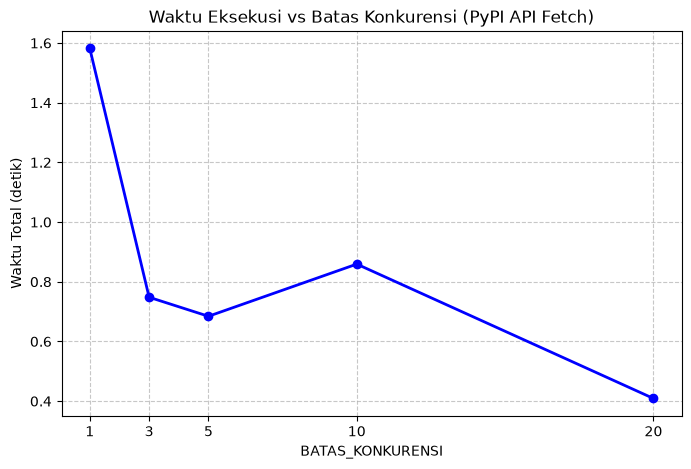

In [ ]:
import asyncio
import time
import aiohttp
import matplotlib.pyplot as plt

# 1. Daftar 25 nama paket PyPI populer yang valid
daftar_paket_banyak = [
    "requests", "numpy", "pandas", "urllib3", "certifi",
    "idna", "charset-normalizer", "typing-extensions", "pip", "setuptools",
    "wheel", "six", "python-dateutil", "s3transfer", "boto3",
    "pytz", "pydantic", "jinja2", "markupsafe", "click",
    "attrs", "cryptography", "pillow", "scipy", "pyyaml"
]

async def fetch_package_info(session, package_name, semaphore):
    url = f"https://pypi.org/pypi/{package_name}/json"
    async with semaphore:
        try:
            async with session.get(url, timeout=10) as response:
                if response.status == 200:
                    data = await response.json()
                    return data['info']['name']
                return None
        except Exception as e:
            return None

async def run_experiment(batas_konkurensi):
    semaphore = asyncio.Semaphore(batas_konkurensi)
    async with aiohttp.ClientSession() as session:
        tasks = [fetch_package_info(session, pkg, semaphore) for pkg in daftar_paket_banyak]
        start_time = time.perf_counter()
        results = await asyncio.gather(*tasks)
        end_time = time.perf_counter()
        return end_time - start_time

async def main_experiments():
    batas_list = [1, 3, 5, 10, 20]
    waktu_eksekusi = []

    print("=== Memulai Eksperimen Skala ===")
    for batas in batas_list:
        waktu = await run_experiment(batas)
        waktu_eksekusi.append(waktu)
        print(f"BATAS_KONKURENSI = {batas:2d} | Waktu Total: {waktu:.4f} detik")

    # Plotting Waktu vs Batas Konkurensi
    plt.figure(figsize=(8, 5))
    plt.plot(batas_list, waktu_eksekusi, marker='o', linewidth=2, color='b')
    plt.title("Waktu Eksekusi vs Batas Konkurensi (PyPI API Fetch)", fontsize=12)
    plt.xlabel("BATAS_KONKURENSI", fontsize=10)
    plt.ylabel("Waktu Total (detik)", fontsize=10)
    plt.xticks(batas_list)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()

# Jalankan dalam environment Jupyter Notebook
await main_experiments()

Peningkatan batas konkurensi dari 1 ke 3 atau 5 memangkas waktu eksekusi secara signifikan. Namun, penambahan batas lebih lanjut (di atas 5–10) hanya memberikan penurunan waktu yang sangat kecil. Fenomena ini sesuai dengan konsep diminishing returns pada Hukum Amdahl, di mana percepatan sistem dibatasi oleh proses serial seperti handshake koneksi, pembacaan data JSON, dan batas kapasitas server. Oleh karena itu, batasan konkurensi 5–10 sudah paling optimal dan efisien.


**2.** Buat 3 coroutine berbeda: satu memakai `asyncio.sleep()`, satu memakai `time.sleep()`, dan satu lagi memakai operasi CPU-bound murni (misalnya hitung faktorial dari angka besar dalam loop, tanpa `await` sama sekali). Jalankan ketiganya dengan `asyncio.gather()` bersama satu coroutine `asyncio.sleep()` lain sebagai "pengukur". Amati dan jelaskan coroutine mana saja yang mengganggu jalannya coroutine pengukur, dan mengapa.

**Jawaban :**
Pengukur melakukan jeda 0.1 detik secara berkala untuk memantau waktu eksekusi riil. Waktu jeda yang stabil di angka 0.10 detik menandakan event loop lancar, sedangkan peningkatan jeda yang tajam mengindikasikan adanya proses yang mengalangi jalur event loop.

In [1]:
import asyncio
import time

# Coroutine Pengukur (Benchmark)
async def coroutine_pengukur():
    print("[Pengukur] Mulai berjalan...")
    for i in range(1, 6):
        await asyncio.sleep(0.5)
        print(f"  [Pengukur] Detik ke-{i * 0.5:.1f} (berjalan lancar)")
    print("[Pengukur] Selesai.")

# 1. Non-blocking (asyncio.sleep)
async def task_asyncio_sleep():
    print("[Task Asyncio Sleep] Mulai (Non-blocking)...")
    await asyncio.sleep(1.5)
    print("[Task Asyncio Sleep] Selesai.")

# 2. Blocking I/O (time.sleep)
async def task_time_sleep():
    print("[Task Time Sleep] Mulai (Blocking)...")
    time.sleep(1.5)  # MENGHAMBAT EVENT LOOP!
    print("[Task Time Sleep] Selesai.")

# 3. Blocking CPU-bound (Hitung Faktorial Besar)
async def task_cpu_bound():
    print("[Task CPU-Bound] Mulai (Blocking CPU tanpa await)...")
    # Operasi hitung faktorial angka sangat besar tanpa await
    hasil = 1
    for i in range(1, 120000):
        hasil *= i
    print("[Task CPU-Bound] Selesai.")

async def uji_blocking(coro_uji, nama_uji):
    print(f"\n================ UJI BERSAMA: {nama_uji} ================")
    # Menjalankan coroutine uji bersamaan dengan coroutine pengukur
    await asyncio.gather(coro_uji(), coroutine_pengukur())

async def main_deteksi_blocking():
    # Pengujian 1: Non-blocking
    await uji_blocking(task_asyncio_sleep, "asyncio.sleep()")
    
    # Pengujian 2: Blocking dengan time.sleep()
    await uji_blocking(task_time_sleep, "time.sleep()")
    
    # Pengujian 3: Blocking dengan CPU-Bound murni
    await uji_blocking(task_cpu_bound, "CPU-Bound (Faktorial)")

await main_deteksi_blocking()


================ UJI BERSAMA: asyncio.sleep() ================
[Task Asyncio Sleep] Mulai (Non-blocking)...
[Pengukur] Mulai berjalan...
  [Pengukur] Detik ke-0.5 (berjalan lancar)
  [Pengukur] Detik ke-1.0 (berjalan lancar)
[Task Asyncio Sleep] Selesai.
  [Pengukur] Detik ke-1.5 (berjalan lancar)
  [Pengukur] Detik ke-2.0 (berjalan lancar)
  [Pengukur] Detik ke-2.5 (berjalan lancar)
[Pengukur] Selesai.

================ UJI BERSAMA: time.sleep() ================
[Task Time Sleep] Mulai (Blocking)...
[Task Time Sleep] Selesai.
[Pengukur] Mulai berjalan...
  [Pengukur] Detik ke-0.5 (berjalan lancar)
  [Pengukur] Detik ke-1.0 (berjalan lancar)
  [Pengukur] Detik ke-1.5 (berjalan lancar)
  [Pengukur] Detik ke-2.0 (berjalan lancar)
  [Pengukur] Detik ke-2.5 (berjalan lancar)
[Pengukur] Selesai.

================ UJI BERSAMA: CPU-Bound (Faktorial) ================
[Task CPU-Bound] Mulai (Blocking CPU tanpa await)...
[Task CPU-Bound] Selesai.
[Pengukur] Mulai berjalan...
  [Pengukur] Detik 

**Penjelasan:**
oroutine yang mengganggu jalannya pengukur adalah time.sleep() dan operasi CPU-bound murni (faktorial tanpa await).   Hal ini terjadi karena arsitektur asyncio berbasis Single-threaded Event Loop yang mengandalkan kerja sama (cooperative multitasking). time.sleep() merupakan pemanggilan sistem yang membekukan seluruh thread utama, sementara perhitungan faktorial tanpa await memonopoli CPU secara penuh. Akibatnya, Event Loop tidak mendapatkan kesempatan untuk beralih mengeksekusi coroutine pengukur, sehingga jeda waktu pengukur menjadi terhambat. Sebaliknya, asyncio.sleep() bersifat non-blocking dan ramah terhadap Event Loop, sehingga tidak mengganggu jalurnya.   

**3:** Producer-Multi-Consumer dengan Prioritas: Modifikasi contoh asyncio.Queue pada bagian 6.4 agar setiap item memiliki "prioritas" (angka 1–3), dan consumer harus memproses item berprioritas tinggi (angka lebih kecil) lebih dulu. (Hint: cari tahu tentang asyncio.PriorityQueue.)

In [4]:
import asyncio
import random

async def producer(queue, name, count):
    print(f"[{name}] Memulai produksi {count} tugas...")
    for i in range(count):
        priority = random.randint(1, 3)  # Prioritas: 1 (Tinggi), 2 (Sedang), 3 (Rendah)
        item_id = f"Tugas-{i+1} dari {name}"
        
        # Dimasukkan sebagai tuple (prioritas, data) agar PriorityQueue bisa menyortir
        await queue.put((priority, item_id))
        print(f"  [{name}] Memasukkan '{item_id}' dengan Prioritas = {priority}")
        await asyncio.sleep(0.1)
    print(f"[{name}] Selesai membuat tugas.")

async def consumer(queue, name):
    while True:
        priority, item_id = await queue.get()
        print(f"    ---> [{name}] Memproses: '{item_id}' | Prioritas: {priority}")
        await asyncio.sleep(0.3)
        queue.task_done()

async def main_priority_queue():
    queue = asyncio.PriorityQueue()

    producers = [
        asyncio.create_task(producer(queue, "Producer-A", 4)),
        asyncio.create_task(producer(queue, "Producer-B", 4))
    ]

    consumers = [
        asyncio.create_task(consumer(queue, f"Consumer-{i+1}")) for i in range(2)
    ]

    await asyncio.gather(*producers)
    await queue.join()

    for c in consumers:
        c.cancel()

await main_priority_queue()

[Producer-A] Memulai produksi 4 tugas...
  [Producer-A] Memasukkan 'Tugas-1 dari Producer-A' dengan Prioritas = 2
[Producer-B] Memulai produksi 4 tugas...
  [Producer-B] Memasukkan 'Tugas-1 dari Producer-B' dengan Prioritas = 3
    ---> [Consumer-1] Memproses: 'Tugas-1 dari Producer-A' | Prioritas: 2
    ---> [Consumer-2] Memproses: 'Tugas-1 dari Producer-B' | Prioritas: 3
  [Producer-A] Memasukkan 'Tugas-2 dari Producer-A' dengan Prioritas = 1
  [Producer-B] Memasukkan 'Tugas-2 dari Producer-B' dengan Prioritas = 3
  [Producer-A] Memasukkan 'Tugas-3 dari Producer-A' dengan Prioritas = 3
  [Producer-B] Memasukkan 'Tugas-3 dari Producer-B' dengan Prioritas = 2
    ---> [Consumer-1] Memproses: 'Tugas-2 dari Producer-A' | Prioritas: 1
    ---> [Consumer-2] Memproses: 'Tugas-3 dari Producer-B' | Prioritas: 2
  [Producer-A] Memasukkan 'Tugas-4 dari Producer-A' dengan Prioritas = 3
  [Producer-B] Memasukkan 'Tugas-4 dari Producer-B' dengan Prioritas = 2
[Producer-A] Selesai membuat tugas.
[P

**Penjelasan:**
Mengganti asyncio.Queue standar dengan asyncio.PriorityQueue. Elemen dimasukkan dalam bentuk tuple (prioritas, data). Python akan secara otomatis memprioritaskan elemen dengan nilai angka terkecil (angka 1 didahulukan dibanding 2 atau 3), sehingga item berprioritas tinggi akan selalu diproses lebih awal oleh consumer.

**4:** Refleksi singkat (maks. 150 kata): Bandingkan pengalaman kalian menulis kode paralel dengan threading (Pertemuan 2), multiprocessing (Pertemuan 3), dan asyncio (pertemuan ini) untuk kasus I/O-bound. Mana yang menurut kalian paling mudah dipahami dan mengapa? Berikan alasan berbasis pengalaman coding kalian, bukan hanya teori.

### Jawaban 
Menurut saya, asyncio lebih mudah dan efisien untuk program I/O-bound dibandingkan threading dan multiprocessing. Threading lebih rentan mengalami race condition, sedangkan multiprocessing membutuhkan sumber daya lebih besar. Sementara itu, asyncio menggunakan async dan await untuk mengatur pergantian tugas. Dengan begitu, program dapat menjalankan banyak tugas secara bersamaan dengan penggunaan sumber daya yang lebih hemat.